# TP 2 - Predicción de lluvia en Australia

## 1. Análisis descriptivo

El objetivo es estudiar las observaciones meteorológicas y preparar el problema de clasificación de `RainTomorrow`. 

En este primer avance se revisa el archivo entregado, describimos sus variables y hacemos un diagnostico de lss faltantes.

In [7]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [9]:
# Cargamos el CSV entregado y convierto Date a fecha para resumir el período.
DATA_PATH = Path("weatherAUS_2026C2.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [11]:
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Variables del archivo

El CSV no incluye un diccionario de datos. Esta primera descripción toma los nombres de las columnas y los valores observados en el archivo
| Variable | Qué representa |
| --- | --- |
| `Unnamed: 0` | Índice que quedó guardado junto con el CSV; no describe el clima. |
| `Date` | Fecha asociada a la observación. |
| `Location` | Ciudad o ubicación de la observación. |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima. |
| `Rainfall` | Lluvia observada en la fecha de la fila. |
| `Evaporation` | Evaporación observada. |
| `Sunshine` | Horas de sol registradas. |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga máxima. |
| `WindDir9am`, `WindDir3pm` | Dirección del viento cerca de las 9 y las 15 h. |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento cerca de las 9 y las 15 h. |
| `Humidity9am`, `Humidity3pm` | Humedad observada cerca de las 9 y las 15 h. |
| `Pressure9am`, `Pressure3pm` | Presión observada cerca de las 9 y las 15 h. |
| `Cloud9am`, `Cloud3pm` | Cobertura de nubes cerca de las 9 y las 15 h. |
| `Temp9am`, `Temp3pm` | Temperatura cerca de las 9 y las 15 h. |
| `RainToday` | Indicador categórico de lluvia en la fecha de la fila. |
| `RainTomorrow` | Indicador de lluvia al día siguiente; es la variable objetivo. |
| `RainfallTomorrow` | Cantidad de lluvia del día siguiente, según el nombre de la columna. Se revisa antes de usarla como predictor. |



In [12]:
# Resumo tipos, valores distintos y rangos numéricos para completar la descripción.
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores distintos": df.nunique(dropna=True),
    "faltantes": df.isna().sum(),
})
display(estructura)

variables_numericas = df.select_dtypes(include="number").drop(columns=["Unnamed: 0"])
rangos = variables_numericas.describe().T[["min", "50%", "max"]]
rangos = rangos.rename(columns={"min": "mínimo observado", "50%": "mediana", "max": "máximo observado"})
display(rangos.round(2))

,tipo,valores distintos,faltantes
Unnamed: 0,int64,145412,0
Date,datetime64[us],3435,0
Location,str,49,0
MinTemp,float64,395,1484
MaxTemp,float64,506,1253
Rainfall,float64,681,3260
Evaporation,float64,358,62754
Sunshine,float64,145,69796
WindGustDir,str,16,10316
WindGustSpeed,float64,120,10253


,mínimo observado,mediana,máximo observado
MinTemp,-9.7,12.0,34.1
MaxTemp,-5.1,22.6,49.1
Rainfall,0.0,0.0,371.0
Evaporation,0.0,4.8,145.0
Sunshine,0.0,8.4,14.5
WindGustSpeed,6.0,38.0,135.0
WindSpeed9am,0.0,13.0,130.0
WindSpeed3pm,0.0,18.0,86.0
Humidity9am,0.0,69.9,100.0
Humidity3pm,0.0,52.0,100.0


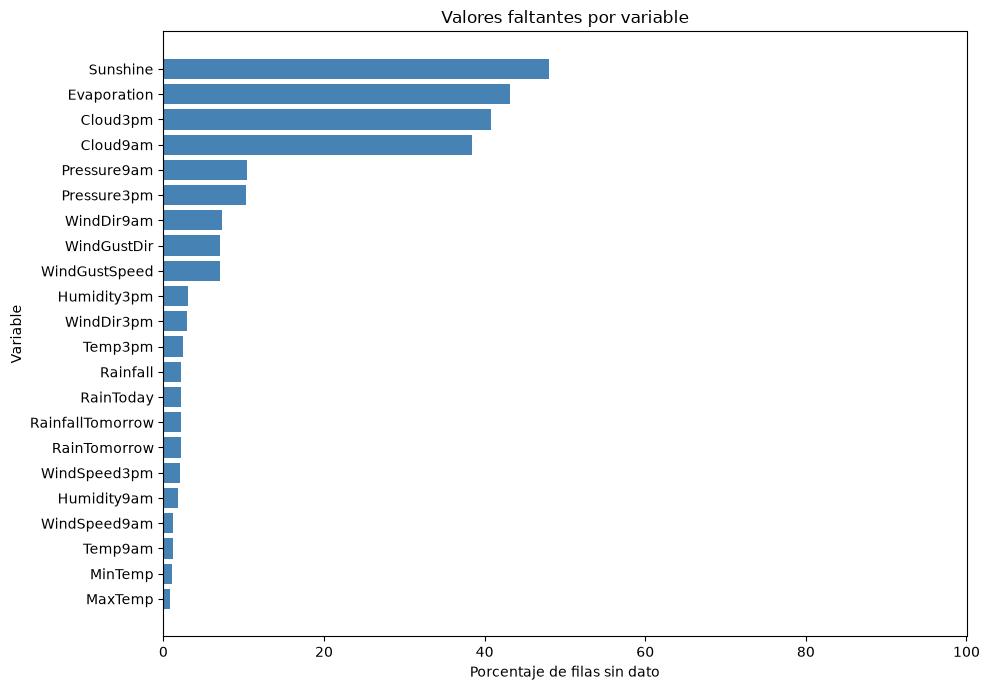

In [7]:
# Grafico el porcentaje de faltantes para comparar variables en la misma escala.
fig, ax = plt.subplots(figsize=(10, 7))
faltantes_ordenados = faltantes.sort_values("porcentaje")
ax.barh(faltantes_ordenados.index, faltantes_ordenados["porcentaje"], color="steelblue")
ax.set_title("Valores faltantes por variable")
ax.set_xlabel("Porcentaje de filas sin dato")
ax.set_ylabel("Variable")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### Análisis de Datos y Decisión sobre los faltantes

Conservamos `Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` en el conjunto de datos porque describen condiciones meteorológicas que pueden aportar información sobre la lluvia: horas de sol, evaporación y cobertura de nubes en dos momentos del día. No eliminaremos las filas por tener faltante en alguna de estas cuatro columnas. Si lo hiciéramos, perderíamos 82.854 registros (56,98 % del archivo); entre las filas con `RainTomorrow` conocido, solo conservaríamos 62.349 (43,86 %). Además, los faltantes varían por ubicación y año. El tratamiento de estos predictores se definirá más adelante, después de separar entrenamiento y prueba.

Se excluirán del conjunto de modelado las filas que no tengan valor en `RainTomorrow`. Esta columna es la variable objetivo: sin conocer si llovió al día siguiente, no hay una respuesta observada con la cual entrenar el modelo ni comprobar después si acertó. Tampoco corresponde completar esa etiqueta con una moda o una mediana, porque eso asignaría una respuesta no observada y alteraría la distribución de clases.

Esta decisión se aplica a las filas sin etiqueta. Los faltantes en las variables que describen las condiciones del día se analizarán por separado y, si se conservan, se tratarán durante el preprocesamiento. Una mediana o una moda puede servir como estrategia para ciertos predictores, pero no reemplaza el valor faltante de `RainTomorrow`.